# Taxi: logistic vs quadratic logistic regression (big classification dataset)

**Data:** UCI *Taxi Service Trajectory* (Porto, ECML PKDD 2015), ~1.7M trips.
**Target:** `CALL_TYPE`: A = booked via the central, B = from a taxi stand, C = hailed on the street.
**Metric:** logistic loss (log-loss).

Step 4 of the lab: we repeat steps 1-3 with **logistic regression** instead of linear
regression: learning curves for the plain and the quadratic model, then cross-validation.

Features (see `lab/data_taxi.py`): hour and weekday of the start, trip duration
(number of GPS points), start/end coordinates and the start-end distance. The columns
`ORIGIN_CALL` / `ORIGIN_STAND` are **not** used because they reveal the label directly.

In [1]:
import sys
sys.path.append("..")  # make the lab/ package (one folder up) importable

import pandas as pd
from IPython.display import display

from lab import FIGURES_DIR, RESULTS_DIR
from lab.experiment import baseline_score, cross_validate_models, run_learning_curve, summarize
from lab.models import make_model
from lab.plotting import plot_learning_curve

# TODO: replace with Jakob's modules once they exist:
#   from lab.split import train_val_split
#   from lab.sampler import sample_training_sets, linear_sizes, log_sizes
from lab.temp_prep import linear_sizes, log_sizes, sample_training_sets, train_val_split

RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.4g}".format)

In [2]:
DATASET = "taxi"
TASK = "classification"
KINDS = ["logistic", "quadratic_logistic"]
N_REPEATS = 5

# RUN_FULL = False: quick run on a random subset (a laptop handles it in seconds).
# RUN_FULL = True: all ~1.7M trips; run it on the JSI servers, e.g.
#   jupyter nbconvert --to notebook --execute --inplace notebooks/taxi.ipynb
RUN_FULL = False
MAX_ROWS = None if RUN_FULL else 20_000
RUN_NAME = f"{DATASET}_{'full' if RUN_FULL else 'small'}"
CV_MAX_ROWS = 100_000   # CV on a random subset of the training part (speed)

## Load the data

In [3]:
from lab.data_taxi import load_taxi

X, y = load_taxi(max_rows=MAX_ROWS)
print(X.shape)
display(X.head())
print("class proportions:")
print(y.value_counts(normalize=True))

(20000, 8)


,hour,weekday,n_points,start_lon,start_lat,end_lon,end_lat,distance_km
0,22,4,44,-8.634,41.17,-8.61,41.15,2.91
1,4,1,30,-8.594,41.17,-8.562,41.15,3.215
2,23,3,104,-8.628,41.16,-8.72,41.27,14.4
3,18,2,39,-8.649,41.17,-8.661,41.16,1.052
4,3,5,30,-8.605,41.16,-8.612,41.15,1.576


class proportions:
CALL_TYPE
B   0.4829
C    0.305
A    0.212
Name: proportion, dtype: float64


## Train / validation split (20%, stratified so both parts keep the class proportions)

In [4]:
X_train, X_val, y_train, y_val = train_val_split(X, y, TASK)
print(f"training part: {len(X_train):,} rows, validation: {len(X_val):,} rows")

training part: 16,000 rows, validation: 4,000 rows


In [5]:
# How many features does each model actually see? (after one-hot / squaring)
# Compare these numbers with the training-set sizes on the x-axis below.
for kind in KINDS:
    prep = make_model(kind).named_steps["prep"].fit(X_train)
    print(f"{kind:>20}: {prep.transform(X_train.iloc[:5]).shape[1]} features")

            logistic: 37 features
  quadratic_logistic: 58 features


With 3 classes, multinomial logistic regression learns one weight per feature *and class*,
so the number of parameters is about 3x the feature count.

## Step 4 (= steps 1 & 2 with logistic regression): learning curves

In [6]:
# Log-spaced sizes from 10 up to the whole training part: 10, 20, 40, ...
sizes = log_sizes(10, len(X_train), 15)
print(sizes)

samples = sample_training_sets(y_train, sizes, N_REPEATS, TASK)
curve = run_learning_curve(X_train, y_train, X_val, y_val, KINDS, samples, TASK)
curve.to_csv(RESULTS_DIR / f"{RUN_NAME}_curve.csv", index=False)

stats = summarize(curve)
display(stats)
print(f"total fitting time: {curve['fit_seconds'].sum():.0f} s")

[10, 17, 29, 49, 82, 139, 236, 400, 678, 1148, 1944, 3292, 5577, 9446, 16000]
size       10


size       17


size       29


size       49


size       82


...

size     5577


size     9446


size    16000


model   size train_score                                \
                                     mean       std    median       q25   
0             logistic     10   0.0002816  0.000127 0.0003001 0.0001719   
1             logistic     17   0.0002536  7.16e-05 0.0002698 0.0001841   
2             logistic     29   0.0002434 7.804e-05  0.000255 0.0002475   
3             logistic     49   0.0002863 8.066e-05 0.0002397 0.0002364   
4             logistic     82      0.2059    0.2847 0.0004359 0.0001963   
5             logistic    139      0.6459   0.07423    0.6599    0.6522   
6             logistic    236      0.7738   0.03509    0.7763    0.7541   
7             logistic    400      0.8891   0.01904    0.8857     0.876   
8             logistic    678      0.9181    0.0205    0.9217    0.9043   
9             logistic   1148       0.954   0.00187     0.954     0.953   
10            logistic   1944      0.9619  0.006121    0.9622    0.9613   
11            logistic   3292      0.9722  0.005494    0.9715    0.9709   
12            logistic   5577      0.9722  0.002176    0.9725    0.9704   
13            logistic   9446      0.9748  0.001667    0.9752    0.9734   
14            logistic  16000      0.9765         0    0.9765    0.9765   
15  quadratic_logistic     10   0.0002437 5.884e-05 0.0002161  0.000195   
16  quadratic_logistic     17   0.0001873 0.0001015 0.0001366 0.0001207   
17  quadratic_logistic     29   0.0002264 8.075e-05 0.0002012 0.0001588   
18  quadratic_logistic     49   0.0002197 7.561e-05 0.0002181 0.0001639   
19  quadratic_logistic     82   0.0002326 0.0001242 0.0002157 0.0001595   
20  quadratic_logistic    139      0.4469     0.136    0.4387    0.3596   
21  quadratic_logistic    236      0.6877   0.05256    0.6587    0.6554   
22  quadratic_logistic    400      0.8319   0.01704     0.832     0.828   
23  quadratic_logistic    678       0.888   0.02274    0.8783    0.8715   
24  quadratic_logistic   1148       0.923   0.01089     0.923    0.9179   
25  quadratic_logistic   1944      0.9384  0.009192    0.9341    0.9337   
26  quadratic_logistic   3292        0.95  0.005319    0.9527     0.945   
27  quadratic_logistic   5577      0.9588  0.005166    0.9595    0.9563   
28  quadratic_logistic   9446      0.9631  0.003388     0.964    0.9613   
29  quadratic_logistic  16000      0.9626         0    0.9626    0.9626   

             val_score                                 
         q75      mean       std median    q25    q75  
0  0.0003112     5.446     1.165  5.593   5.26  6.347  
1  0.0002818     5.943     1.165  5.558  5.392  6.574  
2  0.0002564     10.42     2.663  9.532  9.233  9.659  
3  0.0003337     17.59     3.989  19.55  16.74  19.78  
4     0.4558     14.23     9.282  20.24  4.423  20.82  
5     0.6915     2.731    0.5246  2.525  2.483  2.646  
6     0.7854     1.542    0.1509  1.508  1.473  1.512  
7     0.8922     1.158   0.05271  1.142  1.125  1.167  
8     0.9321     1.058  0.009275  1.063  1.052  1.064  
9     0.9541     1.017  0.006129  1.016  1.014  1.017  
10    0.9631    0.9992  0.001803 0.9986 0.9983  1.001  
11     0.973    0.9892  0.002149 0.9885  0.988 0.9889  
12    0.9733    0.9893  0.000818 0.9896 0.9893 0.9897  
13    0.9759    0.9849 0.0007517 0.9847 0.9842 0.9855  
14    0.9765    0.9842         0 0.9842 0.9842 0.9842  
15 0.0002916     8.224     2.283  8.915  8.102  9.432  
16  0.000272     8.638     2.052  8.545  7.721  9.877  
17 0.0002995     12.39     2.281  11.56  11.49  11.86  
18 0.0002597      17.3     3.167  18.72   17.1  19.31  
19 0.0002424     20.28    0.9207  20.29  19.72  20.69  
20      0.57     7.866     2.734  6.702   6.27  7.818  
21    0.7411     2.945    0.5782  2.686  2.676  2.826  
22    0.8346     1.646     0.296   1.57  1.502  1.745  
23    0.9017     1.164   0.06293   1.16  1.157  1.189  
24    0.9237     1.042   0.05281  1.026   1.01   1.03  
25    0.9473    0.9926   0.01025 0.9859 0.9857  1.004  
26    0.9536    0.9762  0.003233 0.9766 0.9732 0

total fitting time: 14 s


baseline validation log-loss: 1.0425


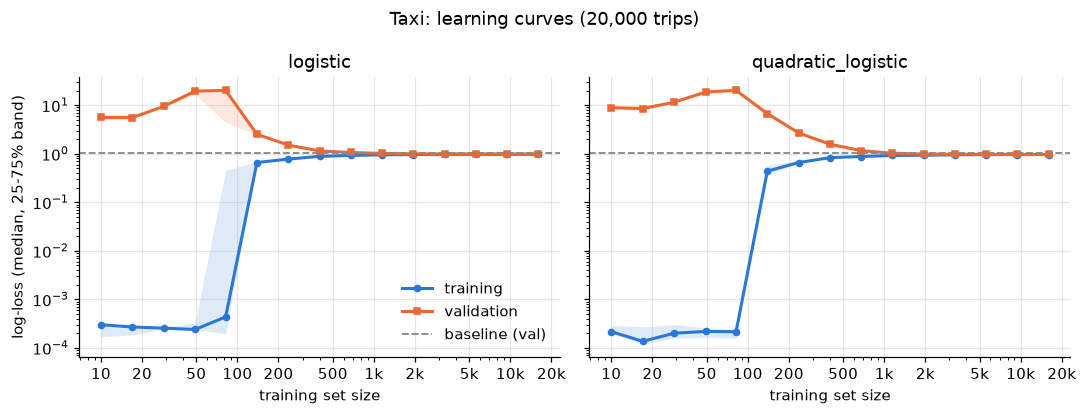

In [7]:
# Reference: always predict the class proportions of the training part.
# Its log-loss is the entropy of the class distribution (~1.04 here).
baseline = baseline_score(X_train, y_train, X_val, y_val, TASK)
print(f"baseline validation log-loss: {baseline:.4f}")

fig = plot_learning_curve(curve, "log-loss", f"Taxi: learning curves ({len(X):,} trips)",
                          baseline=baseline, log_x=True, log_y=True,
                          path=FIGURES_DIR / f"{RUN_NAME}_learning_curves.png")

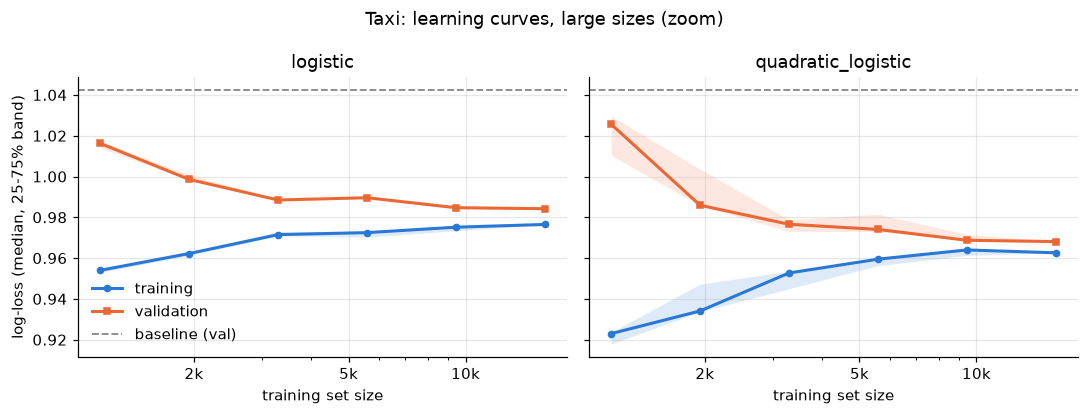

In [8]:
# Zoom in on the large training sets, where the differences are small.
large = curve[curve["size"] >= 1000]
fig = plot_learning_curve(large, "log-loss", "Taxi: learning curves, large sizes (zoom)",
                          baseline=baseline, log_x=True,
                          path=FIGURES_DIR / f"{RUN_NAME}_learning_curves_zoom.png")

### What the curves show

**Small samples.** With few trips (compared to the number of parameters) the three classes
can be separated perfectly in feature space. Without regularization, logistic regression
then pushes its weights towards infinity and predicts probabilities of almost exactly 0
and 1, so the **training log-loss is ~0**. On new trips those over-confident predictions
are often wrong, and log-loss punishes a confident mistake very hard (`-log(p)` with
`p ≈ 0`). That is why the **validation log-loss is far above the baseline**. As with
linear regression it is worst just before the data stop being perfectly separable, which
happens once the number of samples is of the order of the number of parameters (~3x the
feature count printed above); after that point the training loss jumps up and the
validation loss drops quickly.

**Large samples.** The two curves meet at a log-loss only a little below the baseline.
The gap (variance) disappears, but the level stays high: from the time and place of a
trip we can only partly guess how the taxi was called. This is **bias** (the features and
a linear decision rule cannot explain more), not lack of data, so adding even more trips
would barely help.

**Plain vs quadratic.** The quadratic model needs more data before it stops overfitting
(more parameters), but with enough trips it ends slightly lower: being able to model
curved boundaries (e.g. "trips starting near the centre") lowers the bias a bit.

## Step 3 for classification: cross-validation
5-fold stratified CV on (a random subset of) the training part only.

In [9]:
cv = cross_validate_models(X_train, y_train, KINDS, TASK, k=5, max_rows=CV_MAX_ROWS)
cv.to_csv(RESULTS_DIR / f"{RUN_NAME}_cv.csv", index=False)

largest = stats[stats["size"] == stats["size"].max()]
curve_end = pd.DataFrame({
    "model": largest["model"],
    "curve_train": largest[("train_score", "median")],
    "curve_val": largest[("val_score", "median")],
})
comparison = cv.merge(curve_end, on="model")
display(comparison)
print("CV chooses:", cv.loc[cv["cv_mean"].idxmin(), "model"])

,model,cv_mean,cv_std,n_rows,curve_train,curve_val
0,logistic,0.9811,0.002208,16000,0.9765,0.9842
1,quadratic_logistic,0.974,0.00363,16000,0.9626,0.9681


CV chooses: quadratic_logistic


### CV vs. the learning curves

With this many trips all three estimates (training error, validation error, CV error)
are close to each other: the models are too simple to overfit thousands of samples, so
the training error is barely optimistic. CV and the validation curve should agree on the
better model (the quadratic one, by a small margin). Compare this with the small
automobile dataset, where training, validation and CV errors differed by orders of
magnitude.